<a href="https://colab.research.google.com/github/2303880-Mandi/Bridging-Theory-and-Practice-in-Kernel-Based-Dequantization-of-VQML/blob/main/Approved_PQC_Original_Codeipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Date : 08 September 2026\
Author: Mandita Star Rakei\
Purpose: Build a full VPQC with optimization, extract frequency spectrum, confirm with Fourier Series, Build feature map for kernel and finally us KRR

In [ ]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt
from pennylane.templates import StronglyEntanglingLayers
from pennylane.fourier import mark
import itertools
from datetime import datetime

np.random.seed(42)


## Random circuit generator

`build_random_pqc` builds either a *parallel* or *sequential*, *random* PQC automatically from just `num_qubits` and `num_layers` — you never have to hand-write the circuit structure yourself.

In [ ]:
def build_random_pqc(mode, num_qubits, num_layers, trainable_block_layers=1, seed=None,
                      encode_prob=0.7):
    """
    Build a parametrised quantum circuit (PQC) as a Fourier-type model,
    following Schuld, Sweke & Meyer (2021).

    mode : {"parallel", "sequential", "random"}
        "parallel"   -> L = 1 layer; S(x) applied once across all qubits.
        "sequential" -> L = num_layers; S(x) (RX on every qubit) repeated in series.
        "random"     -> L = num_layers; at EACH layer, a random subset of qubits gets
                        an encoding gate, each independently and randomly RX, RY, or RZ
                        (with probability `encode_prob` per qubit per layer). The random
                        structure is drawn ONCE at build time (fixed for this circuit
                        instance), not re-randomized on every call.
    encode_prob : float
        Only used for mode="random". Probability that a given qubit receives an
        encoding gate in a given layer.
    """
    if mode not in ("parallel", "sequential", "random"):
        raise ValueError("mode must be 'parallel', 'sequential', or 'random'")

    if seed is not None:
        np.random.seed(seed)

    dev = qml.device("default.qubit", wires=num_qubits)

    def S(x):
        """Data encoding layer: RX(x) on every qubit, all tagged 'x'."""
        for i in range(num_qubits):
            mark(qml.RX(x, wires=i), "x")

    def W(theta):
        """Trainable layer with weights theta."""
        StronglyEntanglingLayers(theta, wires=range(num_qubits))

    if mode == "parallel":
        num_blocks = 1
        block_layers = num_layers if num_layers else 1

    elif mode == "sequential":
        num_blocks = num_layers
        block_layers = trainable_block_layers

    else:  # mode == "random"
        num_blocks = num_layers
        block_layers = trainable_block_layers

        # --- Draw the random encoding blueprint ONCE, at build time ---
        # blueprint[layer] = list of (qubit_index, gate_class) to apply that layer
        # Every qubit gets an encoding gate in every layer; only the GATE TYPE is random.
        rng = np.random.default_rng(seed)
        gate_choices = [qml.RX]  #, qml.RY, qml.RZ]
        blueprint = []
        for l in range(num_blocks):
            layer_gates = []
            for q in range(num_qubits):
                gate_cls = gate_choices[rng.integers(0, len(gate_choices))]
                layer_gates.append((q, gate_cls))
            blueprint.append(layer_gates)

        print("Random encoding blueprint (layer -> [(qubit, gate), ...]):")
        for l, layer_gates in enumerate(blueprint):
            readable = [(q, g.__name__) for q, g in layer_gates]
            print(f"  layer {l}: {readable}")

        def S_random(x, layer_gates):
            """Apply this layer's encoding gates (every qubit), all tagged 'x'."""
            for q, gate_cls in layer_gates:
                mark(gate_cls(x, wires=q), "x")


    @qml.qnode(dev)
    def circuit(weights, x):
        """U(x) = W^(L+1) S(x) W^(L) ... S(x) W^(1)."""
        for l in range(num_blocks):
            W(weights[l])
            if mode == "random":
                S_random(x, blueprint[l])
            else:
                S(x)
        W(weights[num_blocks])
        return qml.expval(qml.PauliZ(0))

    weights = 2 * np.pi * np.random.random(
        size=(num_blocks + 1, block_layers, num_qubits, 3), requires_grad=True
    )

    return circuit, weights, dev

## Build a Random circuit

Set `num_qubits` and `num_layers` (= r = L, the number of sequential encoding repetitions) below.

In [ ]:
num_qubits = 3
num_layers = 2          # number of random-encoding layers
trainable_block_layers = 5

PQC_circuit, weights, dev = build_random_pqc(
    mode="random",
    num_qubits=num_qubits,
    num_layers=num_layers,
    trainable_block_layers=trainable_block_layers,
    seed=42,
    encode_prob=0.7,     # probability each qubit gets an encoding gate per layer
)

print("Weight tensor shape:", weights.shape)

Random encoding blueprint (layer -> [(qubit, gate), ...]):
  layer 0: [(0, 'RX'), (1, 'RX'), (2, 'RX')]
  layer 1: [(0, 'RX'), (1, 'RX'), (2, 'RX')]
Weight tensor shape: (3, 5, 3, 3)


In [ ]:
# Sanity-check: draw the circuit for a single input value
print(qml.draw(PQC_circuit)(weights, 0.7))


0: ─╭StronglyEntanglingLayers(M0)──RX(0.70, "x")─╭StronglyEntanglingLayers(M1)──RX(0.70, "x") ···
1: ─├StronglyEntanglingLayers(M0)──RX(0.70, "x")─├StronglyEntanglingLayers(M1)──RX(0.70, "x") ···
2: ─╰StronglyEntanglingLayers(M0)──RX(0.70, "x")─╰StronglyEntanglingLayers(M1)──RX(0.70, "x") ···

0: ··· ─╭StronglyEntanglingLayers(M2)─┤  <Z>
1: ··· ─├StronglyEntanglingLayers(M2)─┤     
2: ··· ─╰StronglyEntanglingLayers(M2)─┤     

M0 = 
[[[1.15255478e+00 4.89894304e+00 3.75012014e+00]
  [2.80124980e+00 6.28160922e-01 2.88554589e+00]
  [2.09675304e+00 8.97658691e-01 4.08965289e+00]]

 [[3.54444404e-01 4.53645208e+00 5.89710059e+00]
  [4.89313009e-03 6.23424909e+00 3.87975075e+00]
  [3.84313015e+00 4.43989051e-02 1.44905490e-01]]

 [[3.29725643e+00 2.51240058e+00 2.93209009e-01]
  [6.11828637e+00 1.46254547e+00 5.69297018e-01]
  [3.88543389e+00 2.40307956e+00 6.17782186e+00]]

 [[2.93275775e+00 5.40316493e+00 4.27449833e+00]
  [2.83057028e+00 8.33462091e-02 5.92002823e+00]
  [3.53924425e+00 

## Loss function

In [ ]:
def square_loss(targets, predictions):
    loss = 0
    for t, p in zip(targets, predictions):
        loss += (t - p) ** 2
    loss = loss / len(targets)
    return 0.5 * loss


## Target function to fit

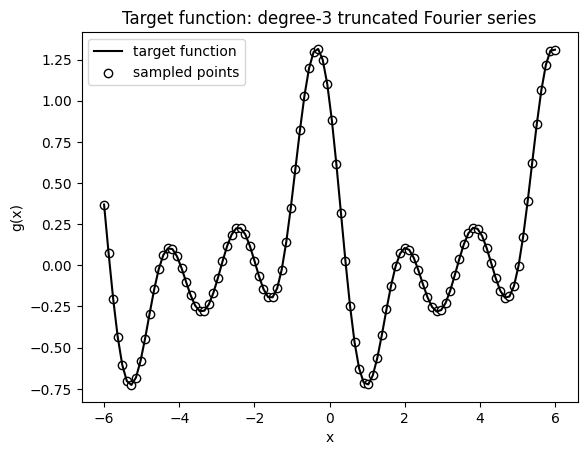

In [ ]:
degree = 3     # degree of the target function
scaling = 1        # scaling of the input data
coeffs = [0.15 + 0.15j] * degree   # coefficients of the non-zero frequencies
coeff0 = 0.1                        # coefficient of the zero frequency


# Uniformly sample the target function at 100 points in [-6, 6]
# amp = 0.4243                                  # feature-space amplitude at EVERY frequency, incl. ω=0
# coeffs = [(amp / 2) * (1 + 1j) / np.sqrt(2)] * degree   # |c| = amp/2, so 2|c| = amp (keeps phase, π/4)
# coeff0 = amp

def target_function(x, _coeffs=coeffs, _coeff0=coeff0, _scaling=scaling):
    """Generate a truncated Fourier series, where the data gets re-scaled.

    _coeffs / _coeff0 / _scaling are bound as default arguments AT DEFINE TIME,
    so this function keeps using THIS target's coefficients even if something
    later in the notebook reassigns the global names coeffs / coeff0 / scaling
    (e.g. cell 19's `emp_freqs, coeffs = check_spectrum_numerically(...)`).
    """
    res = _coeff0
    for idx, coeff in enumerate(_coeffs):
        exponent = np.complex128(_scaling * (idx + 1) * x * 1j)
        conj_coeff = np.conjugate(coeff)
        res += coeff * np.exp(exponent) + conj_coeff * np.exp(-exponent)
    return np.real(res)

x = np.linspace(-6, 6, 100, requires_grad=False)
target_y = np.array([target_function(x_) for x_ in x], requires_grad=False)

plt.plot(x, target_y, c="black", label="target function")
plt.scatter(x, target_y, facecolor="white", edgecolor="black", label="sampled points")
#plt.ylim(-2, 2)
plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("Target function: degree-{0} truncated Fourier series".format(degree))
plt.legend()
plt.show()


In [ ]:
# x1, x2 = 1.0, 4.0        # the box is "on" between x1 and x2 (inside [0, 2π))
# height = 1.0
# degree = 3              # highest frequency used = max of omegas_pos
# scaling = 1

# coeff0 = height * (x2 - x1) / (2 * np.pi)
# coeffs = [height * (np.exp(-1j * n * x1) - np.exp(-1j * n * x2)) / (2j * np.pi * n)
#           for n in range(1, degree + 1)]

# # then your existing target_function(x, _coeffs=coeffs, _coeff0=coeff0, _scaling=scaling) cell,
# # with x = np.linspace(0, 2*np.pi, 100, endpoint=False, requires_grad=False)

# x = np.linspace(-6, 6, 100, requires_grad=False)
# target_y = np.array([target_function(x_) for x_ in x], requires_grad=False)

# plt.plot(x, target_y, c="black", label="target function")
# plt.scatter(x, target_y, facecolor="white", edgecolor="black", label="sampled points")
# #plt.ylim(-2, 2)
# plt.xlabel("x")
# plt.ylabel("g(x)")
# plt.title("Target function: degree-{0} truncated Fourier series".format(degree))
# plt.legend()
# plt.show()

## Untrained PQC output

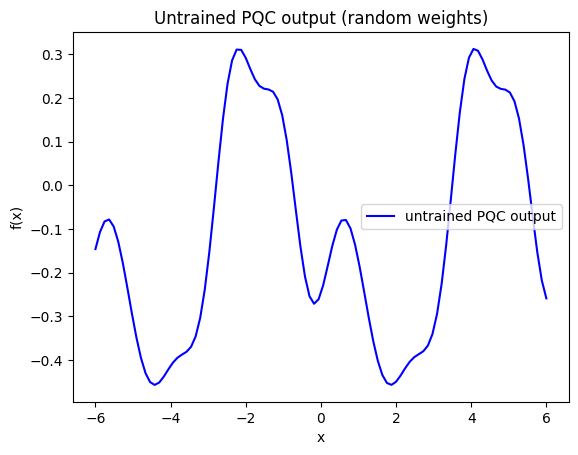

In [ ]:
random_quantum_model_y = [PQC_circuit(weights, x_) for x_ in x]

plt.plot(x, random_quantum_model_y, c="blue", label="untrained PQC output")
#plt.ylim(-1, 1)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Untrained PQC output (random weights)")
plt.legend()
plt.show()


## Train the PQC

In [ ]:
def cost(weights, x, y):
    predictions = [PQC_circuit(weights, x_) for x_ in x]
    return square_loss(y, predictions)


max_steps = 50
opt = qml.AdamOptimizer(0.3)
batch_size = 25
cst = [cost(weights, x, target_y)]  # initial cost

for step in range(max_steps):

    # select a batch of data
    batch_index = np.random.randint(0, len(x), (batch_size,))
    x_batch = x[batch_index]
    y_batch = target_y[batch_index]

    # update the weights by one optimizer step
    weights, _, _ = opt.step(cost, weights, x_batch, y_batch)

    # save, and periodically print, the current cost
    c = cost(weights, x, target_y)
    cst.append(c)
    if (step + 1) % 10 == 0:
        print("Cost at step {0:3}: {1}".format(step + 1, c))

predictions = [PQC_circuit(weights, x_) for x_ in x]



Cost at step  10: 0.03281988063892867
Cost at step  20: 0.03466616766389839
Cost at step  30: 0.04674532155093181
Cost at step  40: 0.01911536327906447
Cost at step  50: 0.018564550886176357


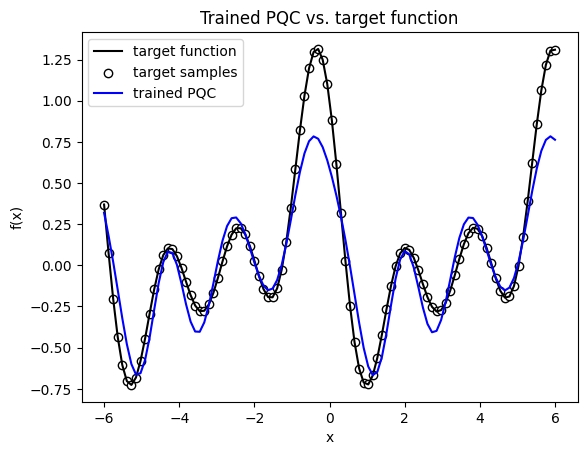

In [ ]:
plt.plot(x, target_y, c="black", label="target function")
plt.scatter(x, target_y, facecolor="white", edgecolor="black", label="target samples")
plt.plot(x, predictions, c="blue", label="trained PQC")
plt.xlabel("x")
plt.ylabel("f(x)")
#plt.ylim(-1, 1)
plt.title("Trained PQC vs. target function")
plt.legend()
plt.show()


## Extract the analytic frequency spectrum Ω (automatic)

In [ ]:
# # The analytic Omega is derived AUTOMATICALLY from the circuit structure --
# # no need to work out the eigenvalue-difference formulas from the paper by
# # hand; qml.fourier.circuit_spectrum inspects the marked encoding gates and
# # does it for you.
# freqs = qml.fourier.circuit_spectrum(PQC_circuit)(weights, x[0])
# for k, v in freqs.items():
#     print(k, ":", v)

# omegas = np.array(sorted(freqs["x"]))
# print("\nExtracted frequency spectrum \u03a9:", omegas)


## Numerically verify the spectrum via FFT

In [ ]:
freqs = qml.fourier.circuit_spectrum(PQC_circuit)(weights, x[0])
omegas = np.array(sorted(freqs["x"]))

def check_spectrum_numerically(build_fn, weights, omega, title, threshold=1e-3):
    N = 64  # samples per period; must exceed 2 * max|omega| to avoid aliasing
    # xs = np.linspace(-np.pi, np.pi, N, endpoint=False)
    xs = np.linspace(0, 2 * np.pi, N, endpoint=False)


    expectation_values = np.array([build_fn(weights, x_) for x_ in xs])

    fft_coeffs = np.fft.fft(expectation_values) / N
    n_index = np.fft.fftfreq(N, d=1.0 / N).astype(int)
    order = np.argsort(n_index)
    n_sorted, c_sorted = n_index[order], fft_coeffs[order]  # keep complex coeffs, not just magnitude
    mag_sorted = np.abs(c_sorted)

    empirical_freqs = n_sorted[mag_sorted > threshold]
    print(f"{title}")
    print(f"  (threshold = {threshold})")
    print("  Empirical nonzero-coefficient frequencies:", empirical_freqs)
    print("  All contained in analytic Omega:",
          set(empirical_freqs).issubset(set(omega.tolist())))

    coeffs_dict = dict(zip(n_sorted.tolist(), c_sorted))
    coeffs_in_omega = {int(w): coeffs_dict[int(w)] for w in omega}

    # fig, ax = plt.subplots(figsize=(9, 3.5))
    # ax.vlines(omega, 0, 1.0, color="lightgray", linewidth=2, label=r"accessible $\Omega$ (analytic)")
    # ax.stem(n_sorted, mag_sorted / mag_sorted.max(), basefmt=" ", linefmt="C0-", markerfmt="C0o")
    # ax.set_xlabel("frequency $n$")
    # ax.set_ylabel("normalized $|c_n|$")
    # ax.set_title(title)
    # ax.legend(loc="upper right")
    # plt.tight_layout()
    # plt.show()
    return empirical_freqs, coeffs_in_omega


emp_freqs, coeffs = check_spectrum_numerically(
    PQC_circuit, weights, omegas,
    "Sequential PQC (num_qubits={}, r=L={}): analytic Omega vs simulated".format(num_qubits, num_layers)
)

print("\nCoefficients:")
for freq, c in sorted(coeffs.items()):
    print(f"  n = {freq:+d}:  c_n = {c.real:+.5f} {'+' if c.imag >= 0 else '-'} {abs(c.imag):.5f}j   |c_n| = {abs(c):.5f}")


#  c_theta: [ 2.16386955e-01  6.31803413e-01 -6.00670710e-01 -1.73326593e-02
#  -4.73858994e-03 -2.06432094e-16 -1.59594560e-16]

Sequential PQC (num_qubits=3, r=L=2): analytic Omega vs simulated
  (threshold = 0.001)
  Empirical nonzero-coefficient frequencies: [-6 -5 -4 -3 -2 -1  0  1  2  3  4  5  6]
  All contained in analytic Omega: False

Coefficients:
  n = -6:  c_n = -0.00025 - 0.00220j   |c_n| = 0.00221
  n = -5:  c_n = -0.02162 - 0.00898j   |c_n| = 0.02341
  n = -4:  c_n = -0.02591 + 0.05612j   |c_n| = 0.06181
  n = -3:  c_n = +0.10782 - 0.10013j   |c_n| = 0.14715
  n = -2:  c_n = +0.11394 - 0.06951j   |c_n| = 0.13347
  n = -1:  c_n = +0.10325 - 0.13717j   |c_n| = 0.17169
  n = +0:  c_n = +0.03622 + 0.00000j   |c_n| = 0.03622
  n = +1:  c_n = +0.10325 + 0.13717j   |c_n| = 0.17169
  n = +2:  c_n = +0.11394 + 0.06951j   |c_n| = 0.13347
  n = +3:  c_n = +0.10782 + 0.10013j   |c_n| = 0.14715
  n = +4:  c_n = -0.02591 - 0.05612j   |c_n| = 0.06181
  n = +5:  c_n = -0.02162 + 0.00898j   |c_n| = 0.02341
  n = +6:  c_n = -0.00025 + 0.00220j   |c_n| = 0.00221


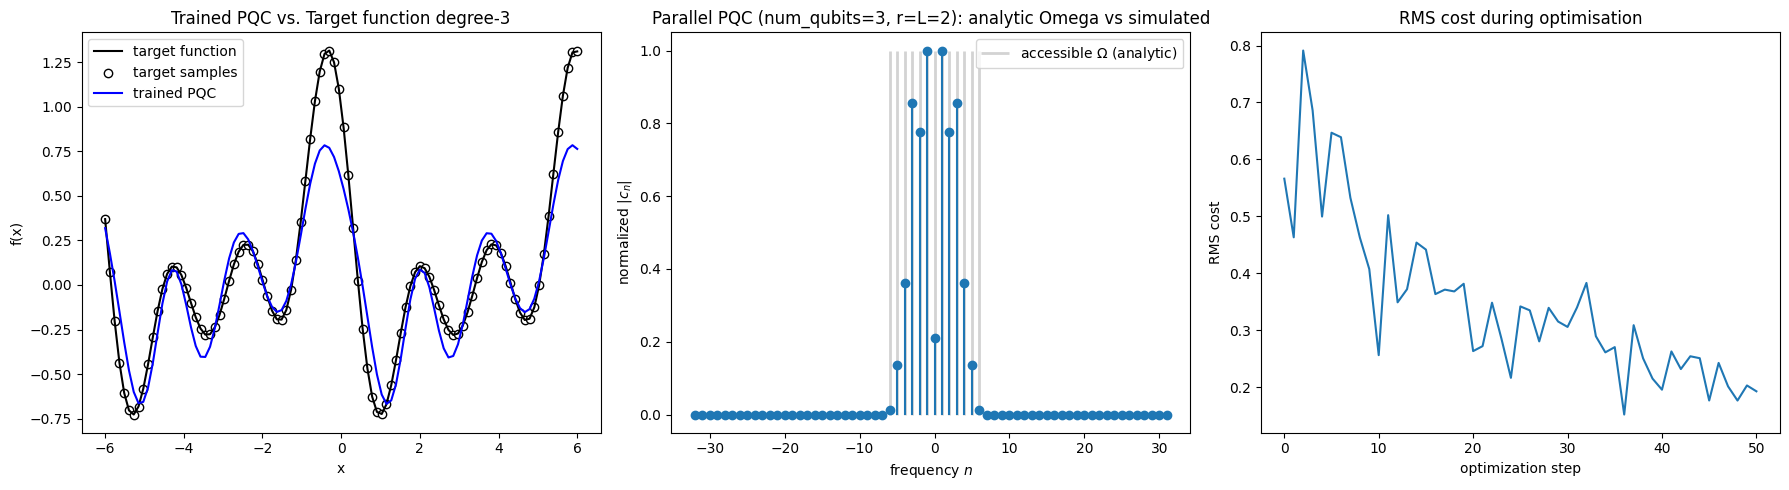

In [ ]:
# --- Combined diagnostics, side by side: RMS cost convergence, trained fit, and frequency-spectrum check ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


# 1) Trained PQC vs. target function
axes[0].plot(x, target_y, c="black", label="target function")
axes[0].scatter(x, target_y, facecolor="white", edgecolor="black", label="target samples")
axes[0].plot(x, predictions, c="blue", label="trained PQC")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].set_title("Trained PQC vs. Target function degree-{0}".format(degree))
axes[0].legend()

# 3) Analytic Omega vs. simulated (FFT) spectrum
N = 64  # samples per period; must exceed 2 * max|omega| to avoid aliasing
xs = np.linspace(0, 2 * np.pi, N, endpoint=False)
expectation_values = np.array([PQC_circuit(weights, x_) for x_ in xs])
fft_coeffs = np.fft.fft(expectation_values) / N
n_index = np.fft.fftfreq(N, d=1.0 / N).astype(int)
order = np.argsort(n_index)
n_sorted, c_sorted = n_index[order], fft_coeffs[order]
mag_sorted = np.abs(c_sorted)

axes[1].vlines(omegas, 0, 1.0, color="lightgray", linewidth=2, label=r"accessible $\Omega$ (analytic)")
axes[1].stem(n_sorted, mag_sorted / mag_sorted.max(), basefmt=" ", linefmt="C0-", markerfmt="C0o")
axes[1].set_xlabel("frequency $n$")
axes[1].set_ylabel("normalized $|c_n|$")
axes[1].set_title("Parallel PQC (num_qubits={}, r=L={}): analytic Omega vs simulated".format(num_qubits, num_layers))
axes[1].legend(loc="upper right")

# 3) RMS cost curve (cst holds square_loss = 0.5 * MSE per step, so RMS = sqrt(2 * cst))
rms_cost = [np.sqrt(2 * c) for c in cst]
axes[2].plot(range(len(rms_cost)), rms_cost, c="C0")
axes[2].set_xlabel("optimization step")
axes[2].set_ylabel("RMS cost")
axes[2].set_title("RMS cost during optimisation")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

plt.tight_layout()
#plt.savefig(rf"C:\Users\cc\Documents\MSc\Research_Quantum\Images\pqc_diagnostics_{timestamp}.png", dpi=300, bbox_inches="tight")
plt.show()

## Verify Ω by reconstructing f(x) as a Fourier series

In [ ]:
# x_fit = np.linspace(-6, 6, 300, requires_grad=False)
# y_model = np.array([PQC_circuit(weights, x_) for x_ in x_fit])

# # Fit Fourier coefficients c_omega via least squares, using ONLY the
# # extracted frequencies omegas
# A = np.exp(1j * np.outer(x_fit, omegas))
# c_omega, *_ = np.linalg.lstsq(A, y_model, rcond=None)

# def fourier_series(x_val):
#     return np.real(np.sum(c_omega * np.exp(1j * omegas * x_val)))

# y_series = np.array([fourier_series(x_) for x_ in x_fit])

# plt.plot(x_fit, y_model, c="blue", label="trained PQC output")
# plt.plot(x_fit, y_series, c="red", linestyle="--", label="Fourier reconstruction")
# plt.xlabel("x")
# plt.ylabel("f(x)")
# plt.title("Verifying extracted \u03a9 via Fourier series fit")
# plt.legend()
# plt.show()

# print("Max reconstruction error:", np.max(np.abs(y_model - y_series)))


# Extract Omega_D with the mirror-pair splitting from Eq. (18)-(21)Potential and Limitations :
Omega_tilde_D = Omega_D U (-Omega_D),   Omega_D ∩ (-Omega_D) = {omega_0}
Omega_D^+     = Omega_D \ {omega_0}

Classical surrogates for quantum learning models (Franz J. Schreiber, Jens Eisert, Johannes Jakob Meyer)\
Explains that once you have the coefficients and feature map, you don't need the QModel anymore\
Extract the frequencies using FFT..


In [ ]:
# Extract Omega_D with the mirror-pair splitting from Eq. (18)-(21)Potential and Limitations :
# Omega_tilde_D = Omega_D U (-Omega_D),   Omega_D ∩ (-Omega_D) = {omega_0}
# Omega_D^+     = Omega_D \ {omega_0}

def get_omega_D(circuit, weights, tag="x"):
    freqs = qml.fourier.circuit_spectrum(circuit)(weights, 0.5)
    omega_tilde_D = sorted(int(w) for w in freqs[tag])   # full mirrored spectrum
    omega_plus = [w for w in omega_tilde_D if w > 0]      # Omega_D^+
    omega_D = [0] + omega_plus                            # Omega_D = {omega_0} U Omega_D^+
    return omega_tilde_D, omega_D, omega_plus


# 2. Extract c_omega(theta) for every omega in Omega_tilde_D
#    IMPORTANT: sample on [0, 2*pi), NOT [-pi, pi)


#TODO : Check the xs and the x, x_fit above the generation 0, 2pi

def extract_c_omega(circuit, weights, omega_tilde_D):
    max_w = max(abs(w) for w in omega_tilde_D) if omega_tilde_D else 0
    N = max(64, 4 * (2 * max_w + 1))                    # oversample past Nyquist
    xs = np.linspace(0, 2 * np.pi, N, endpoint=False)    # correct window ""
    ys = np.array([circuit(weights, x_) for x_ in xs])
    return {w: np.mean(ys * np.exp(-1j * w * xs)) for w in omega_tilde_D}



# 3. Mirror-pair splitting (Eq. 19-20): Potential and Limitations paper
#      a_omega(theta) := c_omega(theta) + c_{-omega}(theta)
#      b_omega(theta) := i*(c_omega(theta) - c_{-omega}(theta))
#    for all omega in Omega_D^+

def split_a_b(c_full, omega_plus):
    a, b = {}, {}
    for w in omega_plus:
        a[w] = c_full[w] + c_full[-w]
        b[w] = 1j * (c_full[w] - c_full[-w])
    return a, b, c_full[0]   # c_omega0(theta) is the third return



# 4. Build c(theta)  (Eq. 22)  and  phi_D(x)  (Eq. 23)
#      c(theta) = sqrt(|Omega_D|) * (c_omega0, a_w1, b_w1, ..., a_wk, b_wk)
#      phi_D(x) = (1/sqrt(|Omega_D|)) * (1, cos(w1 x), sin(w1 x), ..., cos(wk x), sin(wk x))

def build_feature_map(c_omega0, a, b, omega_plus, n_omega_D):
    c_theta = np.sqrt(n_omega_D) * np.array(
        [c_omega0.real] + [val for w in omega_plus for val in (a[w].real, b[w].real)]
    )

    def phi_D(x):
        vec = [1.0]
        for w in omega_plus:
            vec.append(np.cos(w * x))
            vec.append(np.sin(w * x))
        return np.array(vec) / np.sqrt(n_omega_D)

    return c_theta, phi_D


# ============================================================
# Full pipeline, end to end
# ============================================================
def extract_pqc_feature_map(circuit, weights, tag="x"):
    """
    Given a trained (or random) PQC `circuit(weights, x)` with encoding
    gates tagged `tag`, returns (c_theta, phi_D, omega_D) such that
        circuit(weights, x) == np.dot(c_theta, phi_D(x))
    to machine precision -- the explicit classical feature map behind
    kernel-based dequantization, Eq. (21)-(23).
    """
    omega_tilde_D, omega_D, omega_plus = get_omega_D(circuit, weights, tag)
    c_full = extract_c_omega(circuit, weights, omega_tilde_D)
    a, b, c_omega0 = split_a_b(c_full, omega_plus)
    c_theta, phi_D = build_feature_map(c_omega0, a, b, omega_plus, len(omega_D))
    return c_theta, phi_D, omega_D


# ---- usage ----
c_theta, phi_D, omega_D = extract_pqc_feature_map(PQC_circuit, weights)

# sanity check: should match the circuit to ~1e-15
x_test = 1.234
assert abs(PQC_circuit(weights, x_test) - np.dot(c_theta, phi_D(x_test))) < 1e-10

print("Extracted feature map:")
print("  c_theta:", c_theta)
print("  phi_D(x_test):", phi_D(x_test))
print("Omega_D:", omega_D)

Extracted feature map:
  c_theta: [ 0.09582765  0.54635712 -0.72583784  0.60291138 -0.36778888  0.57053398
 -0.52985833 -0.13709143  0.29694228 -0.11439831 -0.04749832 -0.00130872
 -0.01164466]
  phi_D(x_test): [ 0.37796447  0.12490407  0.35672975 -0.2954116   0.23577347 -0.32015052
 -0.20089994  0.08381444 -0.36855431  0.37554602 -0.04268874  0.16439527
  0.34034003]
Omega_D: [0, 1, 2, 3, 4, 5, 6]


In [ ]:


x_plot = np.linspace(-6, 6, 11)# requires_grad=False
y_circuit = np.array([float(PQC_circuit(weights, x_)) for x_ in x_plot])
y_featuremap = np.array([float(np.dot(c_theta, phi_D(x_))) for x_ in x_plot])

# --- Error measurement ---
abs_error = np.abs(y_circuit - y_featuremap)
max_error = np.max(abs_error)
mean_error = np.mean(abs_error)
rmse = np.sqrt(np.mean(abs_error ** 2))

print(f"Max  |f_circuit - f_featuremap| : {max_error:.3e}")
print(f"Mean |f_circuit - f_featuremap| : {mean_error:.3e}")
print(f"RMSE                            : {rmse:.3e}")

# --- Plot ---
# plt.figure(figsize=(9, 5))
# plt.plot(x_plot, y_circuit, color="green", linewidth=2.5,
#          label=r"Trained PQC output $f_\theta(x)$")
# plt.plot(x_plot, y_featuremap, color="orange", linewidth=1.5, linestyle="--",
#          label=r"Feature map $\langle c(\theta), \phi_D(x) \rangle$")
# plt.xlabel("x")
# plt.ylabel("f(x)")
# plt.title(f"Trained PQC vs. feature-map reconstruction (max error = {max_error:.1e})")
# plt.legend()
# plt.tight_layout()
# plt.show()

Max  |f_circuit - f_featuremap| : 8.882e-16
Mean |f_circuit - f_featuremap| : 3.406e-16
RMSE                            : 4.281e-16


In [ ]:
def K_D(x, xp):
    return np.dot(phi_D(x), phi_D(xp))

# kernel = K_D(0.5, 0.9)
# print(f"Kernel value at (0.5, 0.9): {kernel}")

In [ ]:
# x = np.linspace(-6, 6, 100) #, requires_grad=False)
# target_y = np.array([target_function(x_) for x_ in x], requires_grad=False)
# assert len(x) == len(target_y) == 100, (len(x), len(target_y))

In [ ]:
# --- KRR on the PQC feature-map kernel K_D (no reweighting vector) ---
# Uses x, target_y, phi_D, K_D exactly as already defined above. Nothing redefined.

def gram_matrix(A, B):
    """Gram matrix G[i,j] = K_D(A[i], B[j])."""
    return np.array([[K_D(ai, bj) for bj in B] for ai in A])

lam = 1e-6  # ridge regularization strength

M = len(x)
K = gram_matrix(x, x)
alpha = np.linalg.solve(K + lam * np.eye(M), target_y)

def krr_predict(x_new):
    return gram_matrix(x_new, x) @ alpha

krr_pred = krr_predict(x)

# --- Plot: exact same format as the original target-function plot ---
# plt.plot(x, target_y, c="black", label="target function")
# plt.scatter(x, target_y, facecolor="white", edgecolor="black", label="sampled points")
# plt.plot(x, krr_pred, c="red", linestyle="--", label="KRR prediction")
# plt.xlabel("x")
# plt.ylabel("g(x)")
# plt.title("Target function: degree-{0} truncated Fourier series".format(degree))
# plt.legend()
# plt.show()

#print("KRR train RMSE:", np.sqrt(np.mean((krr_pred - target_y) ** 2)))


M =    5   RMSE vs target_y = 3.676e-01
M =   20   RMSE vs target_y = 1.499e-06
M =   30   RMSE vs target_y = 2.388e-07
M =   50   RMSE vs target_y = 1.499e-07
M =   70   RMSE vs target_y = 1.095e-07


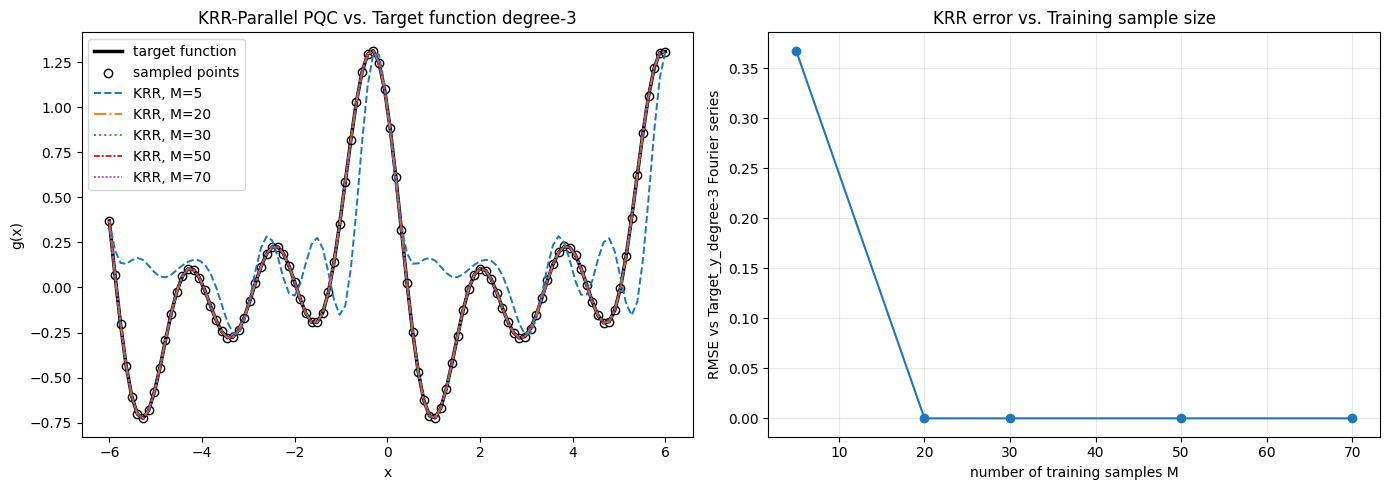

In [ ]:


# --- KRR on K_D, comparing training-set sizes 100 to 500 ---
# x, target_y, target_function, phi_D, K_D used exactly as already defined.
# New sample sets get their own names (x_M, y_M) -- x and target_y untouched.

def gram_matrix(A, B):
    """Gram matrix G[i,j] = K_D(A[i], B[j])."""
    return np.array([[K_D(ai, bj) for bj in B] for ai in A])

lam = 1e-6                          # ridge regularization strength
sample_sizes = [5, 20, 30, 50, 70]  # number of training samples to sweep over
#sample_sizes = [100, 200, 300, 400, 500]  # number of training samples to sweep over

x_lo, x_hi = float(x.min()), float(x.max())   # same domain as the existing x

krr_sweep_results = {}

for M in sample_sizes:
    x_M = np.linspace(x_lo, x_hi, M) # requires_grad=False
    y_M = np.array([target_function(v) for v in x_M]) # requires_grad=False

    K = gram_matrix(x_M, x_M)
    alpha = np.linalg.solve(K + lam * np.eye(M), y_M)

    pred_on_x = gram_matrix(x, x_M) @ alpha       # predict on the ORIGINAL x, for comparison
    rmse = np.sqrt(np.mean((pred_on_x - target_y) ** 2))

    krr_sweep_results[M] = {"x_M": x_M, "y_M": y_M, "alpha": alpha, "pred_on_x": pred_on_x, "rmse": float(rmse)}
    print(f"M = {M:4d}   RMSE vs target_y = {rmse:.3e}")

# --- Combined plot: fit overlay + RMSE convergence, side by side ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: fit overlay
axes[0].plot(x, target_y, c="black", linewidth=2.5, label="target function")
axes[0].scatter(x, target_y, facecolor="white", edgecolor="black", label="sampled points")
for M, style in zip(sample_sizes, ["--", "-.", ":", (0,(3,1,1,1)), (0,(1,1))]):
    axes[0].plot(x, krr_sweep_results[M]["pred_on_x"], linestyle=style, linewidth=1.4, label=f"KRR, M={M}")
axes[0].set_xlabel("x")
axes[0].set_ylabel("g(x)")
axes[0].set_title("KRR-Parallel PQC vs. Target function degree-{0}".format(degree))
axes[0].legend()

# Right panel: RMSE vs sample size
axes[1].plot(sample_sizes, [krr_sweep_results[M]["rmse"] for M in sample_sizes], 'o-')
axes[1].set_xlabel("number of training samples M")
axes[1].set_ylabel("RMSE vs Target_y_degree-{0} Fourier series".format(degree))
axes[1].set_title("KRR error vs. Training sample size")
#axes[1].set_yscale("log")
axes[1].grid(alpha=0.3)

plt.tight_layout()

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
#plt.savefig(rf"C:\Users\cc\Documents\MSc\Research_Quantum\Images\pqc_krr_combined_{timestamp}.png", dpi=300, bbox_inches="tight")
plt.show()

# Re-wighting w

In [ ]:

omegas_pos = np.array([w for w in omega_D if w != 0])  # positive frequencies (Omega_D minus omega_0)

true_coeffs, true_coeff0, true_scaling = target_function.__defaults__
target_freq_mag = {i + 1: abs(c) for i, c in enumerate(true_coeffs)}

eps = 1e-8  # small, non-zero weight for PQC frequencies the target doesn't use
w_ideal = np.array(
    [abs(true_coeff0)] + [target_freq_mag.get(int(om), eps) for om in omegas_pos]
)


# # --- "Not aligned" w: peaks on the frequencies the target does NOT use ---
# w_not_aligned = np.array(
#     [eps] + [1.0 if target_freq_mag.get(int(om), 0) < 1e-9 else eps for om in omegas_pos]
# ) # when w is 1


def K_D_weighted(a, b, omegas_pos, w):
    """K_(D,w)(a,b) = (1/||w||^2) * [w_0^2 + sum_i w_i^2 * cos(omega_i * (a - b))]
    omegas_pos: the positive frequencies in Omega_D (excluding 0)
    w: array of weights, len(w) = len(omegas_pos) + 1 (first entry is for omega_0)
    """
    w = np.array(w)
    w_norm_sq = np.sum(w**2)
    val = w[0]**2  # zero-frequency term (contributes constant)
    for wi, om in zip(w[1:], omegas_pos):
        val += wi**2 * np.cos(om * (a - b))
    return val / w_norm_sq


def gram_matrix_weighted(A, B, omegas_pos, w):
    """Gram matrix G[i,j] = K_D_weighted(A[i], B[j])."""
    return np.array([[K_D_weighted(ai, bj, omegas_pos, w) for bj in B] for ai in A])


# --- Re-run the M-sweep with the re-weighted kernel (uniform RMSEs already in krr_sweep_results) ---
rmse_uniform = [krr_sweep_results[M]["rmse"] for M in sample_sizes]
rmse_reweighted = []

for M in sample_sizes:
    x_M = krr_sweep_results[M]["x_M"]
    y_M = krr_sweep_results[M]["y_M"]

    K = gram_matrix_weighted(x_M, x_M, omegas_pos, w_ideal)
    alpha = np.linalg.solve(K + lam * np.eye(M), y_M)

    pred_on_x = gram_matrix_weighted(x, x_M, omegas_pos, w_ideal) @ alpha
    rmse = np.sqrt(np.mean((pred_on_x - target_y) ** 2))

    rmse_reweighted.append(rmse)
    print(f"M = {M:4d}   RMSE vs target_y (re-weighted) = {rmse:.3e}")




M =    5   RMSE vs target_y (re-weighted) = 1.309e-01
M =   20   RMSE vs target_y (re-weighted) = 1.705e-07
M =   30   RMSE vs target_y (re-weighted) = 1.191e-07
M =   50   RMSE vs target_y (re-weighted) = 7.489e-08
M =   70   RMSE vs target_y (re-weighted) = 5.465e-08


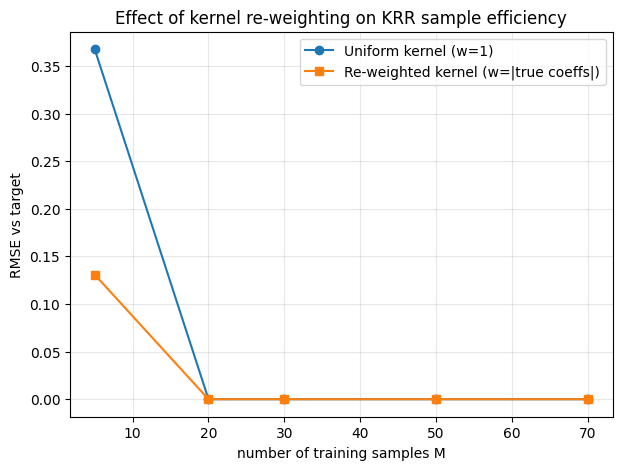

In [ ]:
#--- Plot: uniform vs. re-weighted kernel sample efficiency ---
plt.figure(figsize=(7,5))
plt.plot(sample_sizes, rmse_uniform, 'o-', label="Uniform kernel (w=1)")
plt.plot(sample_sizes, rmse_reweighted, 's-', label="Re-weighted kernel (w=|true coeffs|)")
plt.xlabel("number of training samples M")
plt.ylabel("RMSE vs target")
plt.title("Effect of kernel re-weighting on KRR sample efficiency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:


EPS = 1e-8  # small non-zero weight for "off" frequencies

omegas_pos = np.array([w for w in omega_D if w != 0])   # Omega_D minus omega_0
true_coeffs, true_coeff0, true_scaling = target_function.__defaults__
target_freq_mag = {i + 1: abs(c) for i, c in enumerate(true_coeffs)}


def gram_matrix_weighted(A, B, omegas_pos, w):
    """G[i,j] = (1/||w||^2) * [w0^2 + sum_k w_k^2 cos(omega_k (A_i - B_j))]  (vectorised)."""
    A, B, w = np.asarray(A), np.asarray(B), np.asarray(w)
    diff = A[:, None] - B[None, :]
    cos_terms = np.cos(diff[..., None] * omegas_pos)
    return (w[0] ** 2 + cos_terms @ (w[1:] ** 2)) / np.sum(w ** 2)


def check_w(name, w):
    """Sanity checks on a weight vector."""
    w = np.asarray(w)
    assert len(w) == len(omegas_pos) + 1, "w must have len(omegas_pos)+1 entries"
    print(f"[{name}]")
    print("  omegas (0 first):", np.concatenate([[0], omegas_pos]).astype(int))
    print("  w               :", np.round(w, 4))
    print("  active freqs (w > 1e-6):", np.concatenate([[0], omegas_pos])[w > 1e-6].astype(int))
    G = gram_matrix_weighted(x_M_check, x_M_check, omegas_pos, w)
    print("  K(a,a) == 1 :", np.allclose(np.diag(G), 1.0), "| min eigenvalue:", f"{np.linalg.eigvalsh(G).min():.2e}")


def krr_sweep(name, w):
    """Run KRR with kernel weights w for every M. Returns list of RMSEs."""
    rmses = []
    for M in sample_sizes:
        x_M = krr_sweep_results[M]["x_M"]
        y_M = krr_sweep_results[M]["y_M"]
        K = gram_matrix_weighted(x_M, x_M, omegas_pos, w)
        alpha = np.linalg.solve(K + lam * np.eye(M), y_M)
        pred = gram_matrix_weighted(x, x_M, omegas_pos, w) @ alpha
        rmses.append(np.sqrt(np.mean((pred - target_y) ** 2)))
        print(f"  {name:12s} M = {M:4d}   RMSE = {rmses[-1]:.3e}")
    return rmses


x_M_check = krr_sweep_results[sample_sizes[0]]["x_M"]   # small set used only for the kernel sanity check
results = {}   # filled cell by cell below

In [ ]:
def build_w(w0, spec, default=0.0, normalize=True):
    """
    w0   : weight on omega = 0
    spec : dict {omega: value} -> unspecified freqs get `default`
           or list/array of length len(omegas_pos)
    """
    if isinstance(spec, dict):
        w = np.array([spec.get(int(om), default) for om in omegas_pos], dtype=float)
    else:
        w = np.asarray(spec, dtype=float)
        assert len(w) == len(omegas_pos), (
            f"spec has length {len(w)}, expected {len(omegas_pos)}"
        )
    full = np.concatenate([[w0], w])
    return full / np.linalg.norm(full) if normalize else full

In [ ]:
w_variants = {
    "Custom A (only ω=2,3)":  build_w(w0=0.0, spec={om: 1.0 for om in range(2, 4)}, default=0.0),
    #"Custom C (uniform 1/2)": build_w(w0=0.2, spec=np.full(len(omegas_pos), 0.2)),
    "Custom B (mixed)":       build_w(w0=1.0, spec={1: 0.2, 3: 0.5}, default=0.0),
    "Ideal (w=|true coeffs|)": build_w(abs(true_coeff0), target_freq_mag, default=1e-8)
    #"KTA-learned": w_kta / np.linalg.norm(w_kta),   # your actual w, length 1+len(omegas_pos)
}

results = {}
for name, w in w_variants.items():
    results[name] = krr_sweep(name, w)

  Custom A (only ω=2,3) M =    5   RMSE = 4.248e-01
  Custom A (only ω=2,3) M =   20   RMSE = 3.132e-01
  Custom A (only ω=2,3) M =   30   RMSE = 3.120e-01
  Custom A (only ω=2,3) M =   50   RMSE = 3.115e-01
  Custom A (only ω=2,3) M =   70   RMSE = 3.114e-01
  Custom B (mixed) M =    5   RMSE = 9.403e+00
  Custom B (mixed) M =   20   RMSE = 3.003e-01
  Custom B (mixed) M =   30   RMSE = 2.994e-01
  Custom B (mixed) M =   50   RMSE = 2.990e-01
  Custom B (mixed) M =   70   RMSE = 2.990e-01
  Ideal (w=|true coeffs|) M =    5   RMSE = 1.309e-01
  Ideal (w=|true coeffs|) M =   20   RMSE = 1.705e-07
  Ideal (w=|true coeffs|) M =   30   RMSE = 1.191e-07
  Ideal (w=|true coeffs|) M =   50   RMSE = 7.489e-08
  Ideal (w=|true coeffs|) M =   70   RMSE = 5.465e-08


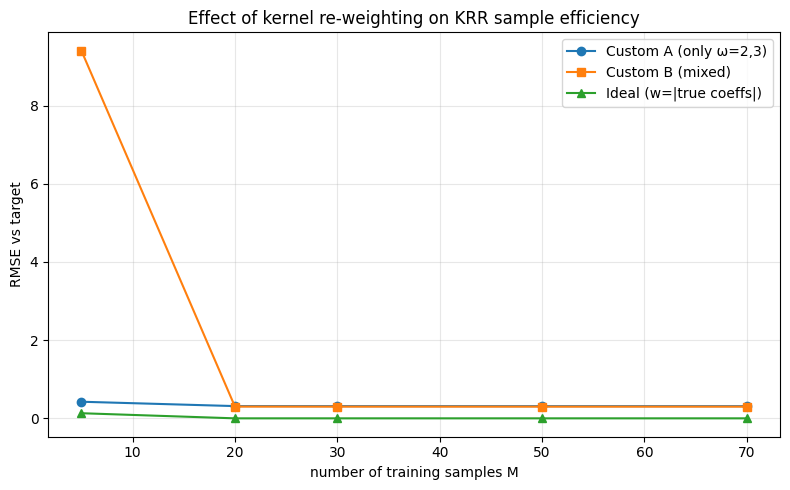

In [ ]:
markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
fig, ax = plt.subplots(figsize=(8, 5))
for i, (name, rmses) in enumerate(results.items()):
    ax.plot(sample_sizes, rmses, marker=markers[i % len(markers)], label=name)
ax.set_xlabel("number of training samples M")
ax.set_ylabel("RMSE vs target")
ax.set_title("Effect of kernel re-weighting on KRR sample efficiency")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

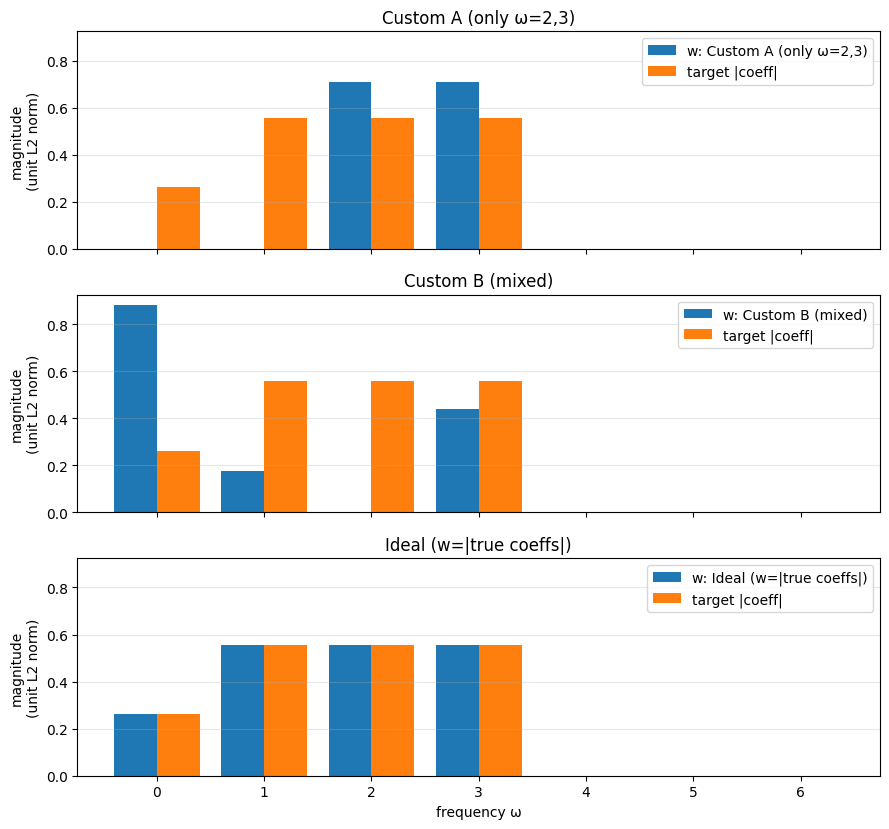

In [ ]:
omegas_all = np.concatenate([[0], omegas_pos]).astype(int)

# target magnitude per frequency (0 for frequencies the target doesn't use)
target_vec = np.array([abs(true_coeff0)] +
                      [target_freq_mag.get(int(om), 0.0) for om in omegas_pos])

def unit(v):
    v = np.abs(np.asarray(v, dtype=float))
    return v / np.linalg.norm(v)

n = len(w_variants)
fig, axes = plt.subplots(n, 1, figsize=(9, 2.8 * n), sharex=True, sharey=True, squeeze=False)
xpos = np.arange(len(omegas_all))
bw = 0.4

for ax, (name, w) in zip(axes[:, 0], w_variants.items()):
    ax.bar(xpos - bw / 2, unit(w), width=bw, color="tab:blue", label=f"w: {name}")
    ax.bar(xpos + bw / 2, unit(target_vec), width=bw, color="tab:orange", label="target |coeff|")
    ax.set_ylabel("magnitude\n(unit L2 norm)")
    ax.set_title(name)
    ax.grid(alpha=0.3, axis="y")
    ax.legend(loc="upper right")

axes[-1, 0].set_xticks(xpos)
axes[-1, 0].set_xticklabels(omegas_all)
axes[-1, 0].set_xlabel("frequency ω")
fig.tight_layout()
plt.show()